# PyTorch Dataset & DataLoader — A Professional, End-to-End Guide

**From raw tabular data to shuffled mini-batches and a trained neural network**

This notebook builds on a small custom `Dataset` and `DataLoader` example and turns it into a complete, reproducible workflow. You will create a synthetic classification dataset, inspect and prepare it, implement a custom PyTorch dataset, construct efficient data loaders, visualize how mini-batches work, and train a small neural network.

> **Core idea:** `Dataset` defines *what one sample looks like*; `DataLoader` defines *how samples are grouped and delivered to your model*.

| Notebook detail | Value |
|---|---|
| Framework | PyTorch |
| Learning task | Binary classification |
| Data | Synthetic, two-feature tabular data |
| Main concepts | `Dataset`, `DataLoader`, batching, shuffling, `drop_last`, train/test split |
| Final exercise | Train and evaluate a small neural network |

---

## Learning outcomes

By the end, you should be able to:

1. Explain the roles of `Dataset` and `DataLoader` and how they work together.
2. Build a custom dataset by implementing `__len__()` and `__getitem__()`.
3. Convert NumPy data into correctly typed PyTorch tensors.
4. Split and scale data without leaking test-set information.
5. Configure batch size, shuffling, worker processes, and incomplete batches.
6. Inspect batch dimensions and verify that the data pipeline is correct.
7. Use a `DataLoader` inside a real PyTorch training loop.

## Notebook map

1. [Environment and reproducibility](#1-environment-and-reproducibility)
2. [Create and explore the dataset](#2-create-and-explore-the-dataset)
3. [Prepare the train and test sets](#3-prepare-the-train-and-test-sets)
4. [Build a custom Dataset](#4-build-a-custom-dataset)
5. [Create and inspect DataLoaders](#5-create-and-inspect-dataloaders)
6. [Understand batching, shuffling, and drop_last](#6-understand-batching-shuffling-and-drop_last)
7. [Train a neural network with mini-batches](#7-train-a-neural-network-with-mini-batches)
8. [Evaluate, visualize, and make predictions](#8-evaluate-visualize-and-make-predictions)
9. [Summary and practice tasks](#9-summary-and-practice-tasks)

## 1. Environment and reproducibility

We will use a small set of standard libraries. No external dataset download is required, so the notebook can run offline once the dependencies are installed.

In [1]:
# If needed, install dependencies in your notebook environment:
# %pip install torch scikit-learn pandas matplotlib

import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

PyTorch: 2.11.0+cpu
NumPy: 2.1.3
Pandas: 2.2.3


In [2]:
# Set seeds so that the data split, initial weights, and example order are repeatable.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Keep CPU execution predictable for this small demonstration.
torch.set_num_threads(1)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Selected device: {DEVICE}")

Selected device: cpu


### The data pipeline at a glance

A typical tabular PyTorch pipeline follows this sequence:

**Raw data → preprocessing → tensors → Dataset → DataLoader → model**

The `Dataset` is responsible for retrieving an individual sample. The `DataLoader` wraps that dataset and handles batching, shuffling, and iteration.

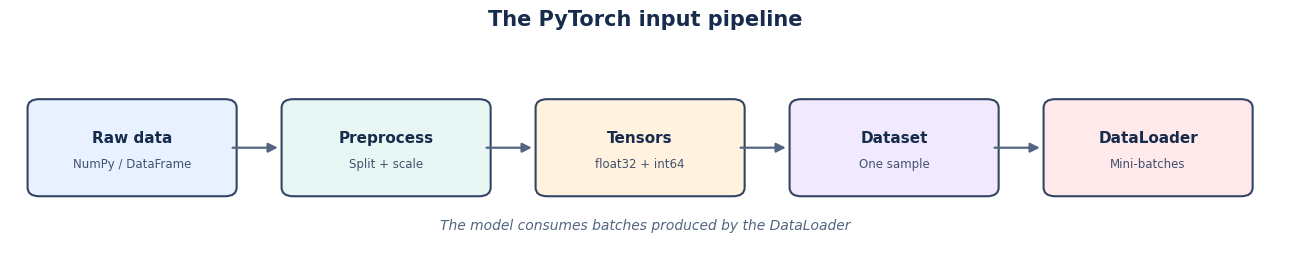

In [3]:
# A simple visual map of the pipeline
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 3)
ax.axis("off")

steps = [
    (0.3, "Raw data", "NumPy / DataFrame", "#E8F1FF"),
    (2.9, "Preprocess", "Split + scale", "#E8F7F3"),
    (5.5, "Tensors", "float32 + int64", "#FFF2DF"),
    (8.1, "Dataset", "One sample", "#F1EAFE"),
    (10.7, "DataLoader", "Mini-batches", "#FFE9EA"),
]
for x, title, subtitle, fill in steps:
    patch = FancyBboxPatch((x, 1.0), 1.9, 1.1,
        boxstyle="round,pad=0.12,rounding_size=0.12",
        linewidth=1.5, edgecolor="#344563", facecolor=fill)
    ax.add_patch(patch)
    ax.text(x + 0.95, 1.68, title, ha="center", va="center",
            fontsize=11, fontweight="bold", color="#172B4D")
    ax.text(x + 0.95, 1.32, subtitle, ha="center", va="center",
            fontsize=8.5, color="#42526E")
for x in [2.25, 4.85, 7.45, 10.05]:
    ax.add_patch(FancyArrowPatch((x, 1.55), (x + 0.52, 1.55),
        arrowstyle="-|>", mutation_scale=14, linewidth=1.6, color="#526581"))
ax.text(6.5, 0.42, "The model consumes batches produced by the DataLoader",
        ha="center", fontsize=10, color="#526581", style="italic")
ax.set_title("The PyTorch input pipeline", fontsize=15, fontweight="bold", pad=12, color="#172B4D")
plt.tight_layout()
plt.show()

## 2. Create and explore the dataset

We will generate a two-dimensional binary classification dataset. Two features make the data easy to visualize, while a larger sample count gives the `DataLoader` enough data to form many mini-batches.

In [4]:
# Generate a reproducible binary classification dataset.
X_numpy, y_numpy = make_classification(
    n_samples=1_200,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    class_sep=1.45,
    flip_y=0.035,
    random_state=SEED,
)

feature_names = ["feature_1", "feature_2"]
print("Feature matrix shape:", X_numpy.shape)
print("Target vector shape:", y_numpy.shape)

Feature matrix shape: (1200, 2)
Target vector shape: (1200,)


In [5]:
# Convert the generated arrays into a DataFrame for convenient inspection.
df = pd.DataFrame(X_numpy, columns=feature_names)
df["target"] = y_numpy

display(df.head(8))

,feature_1,feature_2,target
0,0.123463,2.100493,1
1,1.831128,-2.389501,0
2,1.830644,1.675839,1
3,2.496847,0.365163,1
4,1.641293,1.396232,1
5,-1.236193,-1.071850,0
6,1.341974,0.170010,1
7,1.754371,-1.520446,0


In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   feature_1  1200 non-null   float64
 1   feature_2  1200 non-null   float64
 2   target     1200 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 28.3 KB


In [7]:
# Descriptive statistics help reveal scale, spread, and possible outliers.
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
feature_1,1200.0,1.438,0.937,-2.676,0.914,1.427,1.938,5.063
feature_2,1200.0,-0.017,1.637,-4.517,-1.512,0.627,1.452,2.769
target,1200.0,0.501,0.500,0.000,0.000,1.000,1.000,1.000


In [8]:
class_names = {0: "Class 0", 1: "Class 1"}
class_counts = df["target"].value_counts().sort_index()
class_counts.index = [class_names[int(i)] for i in class_counts.index]

print("Class counts:")
display(class_counts.to_frame("samples"))
print("Class proportions:")
display((class_counts / len(df)).rename("proportion").to_frame().round(3))

Class counts:


,samples
Class 0,599
Class 1,601


Class proportions:


,proportion
Class 0,0.499
Class 1,0.501


In [9]:
# Consistent visual theme for the notebook's charts.
NAVY = "#17324D"
BLUE = "#3478C8"
ORANGE = "#F29E4C"
TEAL = "#2A9D8F"
PURPLE = "#8067B7"
LIGHT_BG = "#F6F8FB"
GRID = "#DCE3EC"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": LIGHT_BG,
    "axes.edgecolor": "#C7D0DC",
    "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY,
    "xtick.color": "#526581",
    "ytick.color": "#526581",
    "text.color": NAVY,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "grid.color": GRID,
    "grid.alpha": 0.8,
    "figure.dpi": 120,
    "savefig.dpi": 180,
})

CLASS_COLORS = {0: BLUE, 1: ORANGE}

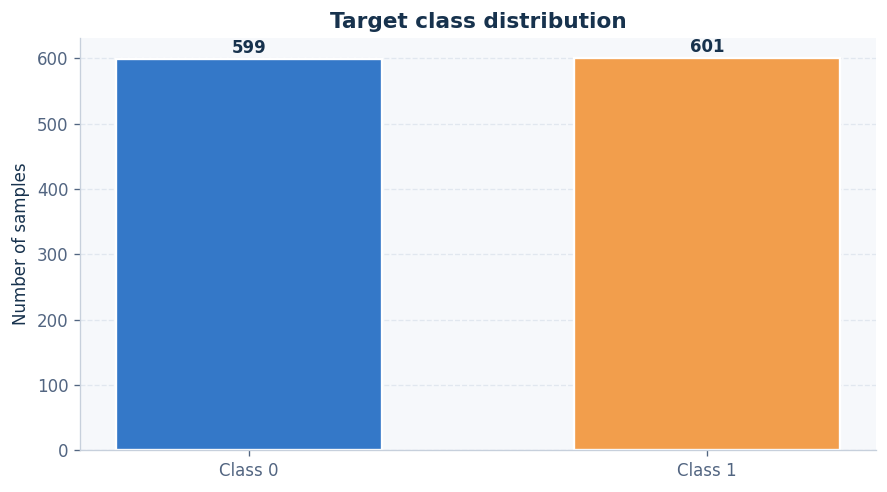

In [10]:
# Visualization 1: class balance.
fig, ax = plt.subplots(figsize=(7.5, 4.2))
labels = ["Class 0", "Class 1"]
values = [int(df["target"].value_counts().get(i, 0)) for i in [0, 1]]
bars = ax.bar(labels, values, color=[BLUE, ORANGE], width=0.58, edgecolor="white", linewidth=1.4)
ax.set_title("Target class distribution")
ax.set_ylabel("Number of samples")
ax.grid(axis="y", linestyle="--")
ax.set_axisbelow(True)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value + max(values)*0.015,
            f"{value:,}", ha="center", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

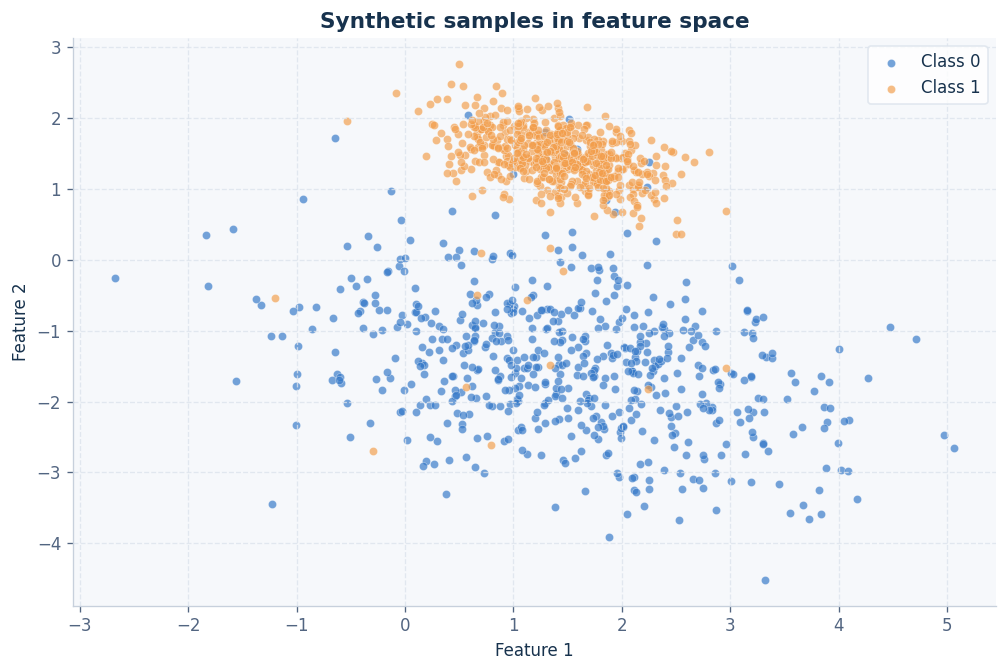

In [11]:
# Visualization 2: feature space, colored by target class.
fig, ax = plt.subplots(figsize=(8.5, 5.7))
for label, color in CLASS_COLORS.items():
    subset = df[df["target"] == label]
    ax.scatter(subset["feature_1"], subset["feature_2"],
               s=24, alpha=0.68, c=color, label=class_names[label],
               edgecolors="white", linewidths=0.25)
ax.set_title("Synthetic samples in feature space")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(frameon=True, facecolor="white", edgecolor=GRID)
ax.grid(linestyle="--")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

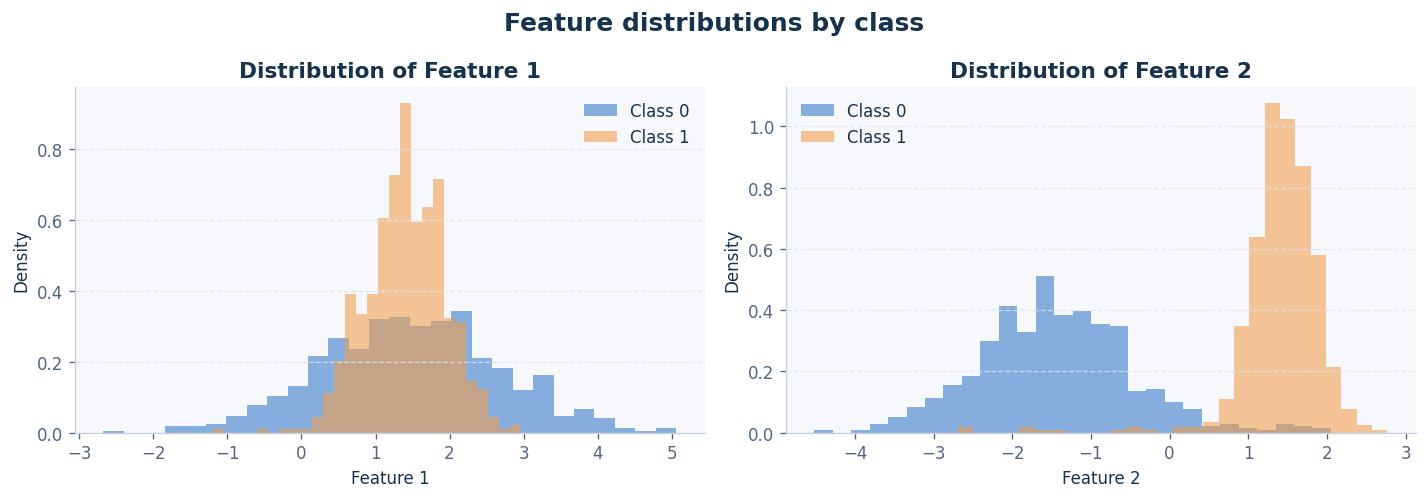

In [12]:
# Visualization 3: feature distributions, separated by class.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, feature in zip(axes, feature_names):
    for label, color in CLASS_COLORS.items():
        values = df.loc[df["target"] == label, feature]
        ax.hist(values, bins=28, alpha=0.58, color=color,
                label=class_names[label], density=True)
    ax.set_title(f"Distribution of {feature.replace('_', ' ').title()}")
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Density")
    ax.grid(axis="y", linestyle="--")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Feature distributions by class", fontsize=15, fontweight="bold", color=NAVY)
plt.tight_layout()
plt.show()

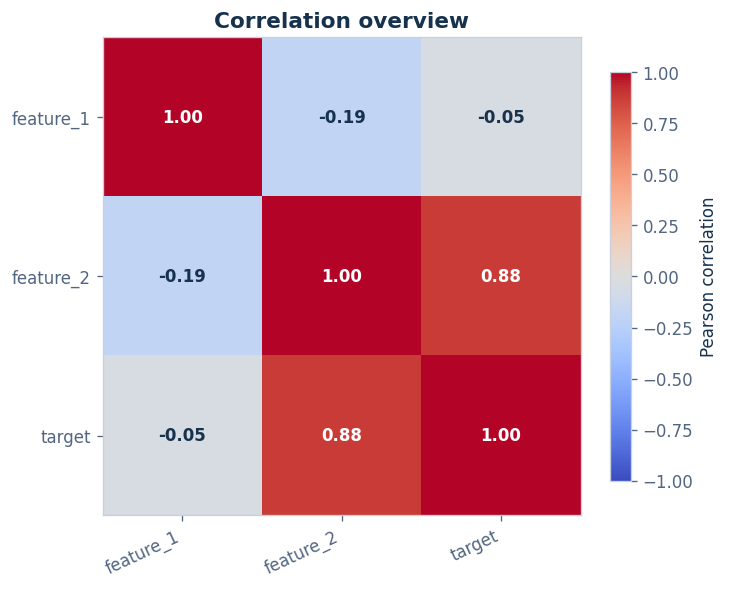

In [13]:
# Visualization 4: feature correlation matrix.
corr = df[feature_names + ["target"]].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.1))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=25, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if abs(value) > 0.55 else NAVY, fontweight="bold")
ax.set_title("Correlation overview")
fig.colorbar(image, ax=ax, shrink=0.82, label="Pearson correlation")
plt.tight_layout()
plt.show()

### What we learned from the exploratory analysis

- Each row represents one observation and each feature column is an input variable.
- The `target` column is the label the model will learn to predict.
- Scatter plots show how the two classes occupy the feature space.
- Distribution and correlation charts are useful diagnostics; they do not replace a proper train/test evaluation.

Next, we split the data before fitting the scaler. This prevents information from the test set from influencing preprocessing.

## 3. Prepare the train and test sets

The test set represents unseen data. We use a stratified split to preserve approximately the same class proportions in both subsets. `StandardScaler` is fitted on the training features only, then applied to both subsets.

In [14]:
X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(
    X_numpy,
    y_numpy,
    test_size=0.20,
    random_state=SEED,
    stratify=y_numpy,
)

print(f"Training samples: {len(X_train_np):,}")
print(f"Test samples:     {len(X_test_np):,}")

Training samples: 960
Test samples:     240


In [15]:
# Fit only on training data, then transform both sets.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_test_scaled = scaler.transform(X_test_np)

print("Training means after scaling:", X_train_scaled.mean(axis=0).round(3))
print("Training std after scaling:   ", X_train_scaled.std(axis=0).round(3))

Training means after scaling: [-0.  0.]
Training std after scaling:    [1. 1.]


,Training,Test
Class 0,479,120
Class 1,481,120


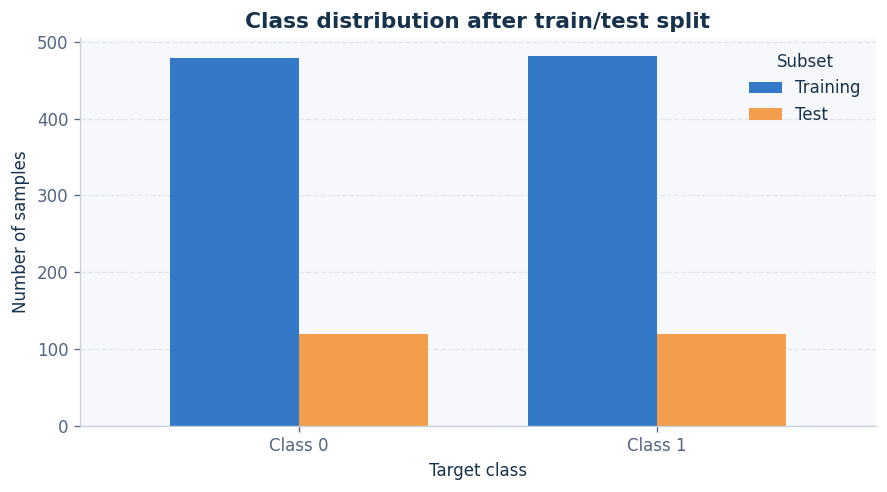

In [16]:
# Compare class counts across the split.
split_counts = pd.DataFrame({
    "Training": pd.Series(y_train_np).value_counts().sort_index(),
    "Test": pd.Series(y_test_np).value_counts().sort_index(),
}).fillna(0).astype(int)
split_counts.index = [class_names[int(i)] for i in split_counts.index]
display(split_counts)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
split_counts.plot(kind="bar", ax=ax, color=[BLUE, ORANGE], width=0.72)
ax.set_title("Class distribution after train/test split")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of samples")
ax.grid(axis="y", linestyle="--")
ax.set_axisbelow(True)
ax.legend(title="Subset", frameon=False)
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Convert arrays to PyTorch tensors

For this classification task:

- **Features:** `torch.float32`, because neural-network layers operate on floating-point values.
- **Labels:** `torch.long`, because `nn.CrossEntropyLoss` expects class indices with integer (`long`) dtype.

A common source of errors is passing floating-point labels to `CrossEntropyLoss` or integer features to a linear layer.

In [17]:
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_np, dtype=torch.long)
y_test = torch.tensor(y_test_np, dtype=torch.long)

print("X_train:", X_train.shape, X_train.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test: ", X_test.shape, X_test.dtype)
print("y_test: ", y_test.shape, y_test.dtype)

X_train: torch.Size([960, 2]) torch.float32
y_train: torch.Size([960]) torch.int64
X_test:  torch.Size([240, 2]) torch.float32
y_test:  torch.Size([240]) torch.int64


In [18]:
# Basic assertions catch shape and type issues before training begins.
assert X_train.ndim == 2, "Features must be a 2D tensor."
assert y_train.ndim == 1, "Labels must be a 1D tensor."
assert len(X_train) == len(y_train), "Training features and labels must align."
assert len(X_test) == len(y_test), "Test features and labels must align."
assert X_train.dtype == torch.float32
assert y_train.dtype == torch.long
print("Data validation passed.")

Data validation passed.


## 4. Build a custom Dataset

A PyTorch map-style dataset is an object that supports two essential methods:

- `__len__()` returns the number of samples.
- `__getitem__(index)` returns the sample at a requested index.

The dataset does not decide the batch size. It returns one sample at a time; the `DataLoader` combines samples into batches.

In [19]:
class TabularDataset(Dataset):
    """A simple map-style Dataset for tabular classification data."""

    def __init__(self, features: torch.Tensor, labels: torch.Tensor):
        if not isinstance(features, torch.Tensor) or not isinstance(labels, torch.Tensor):
            raise TypeError("features and labels must both be PyTorch tensors.")
        if features.ndim != 2:
            raise ValueError("features must have shape [number_of_samples, number_of_features].")
        if labels.ndim != 1:
            raise ValueError("labels must have shape [number_of_samples].")
        if len(features) != len(labels):
            raise ValueError("features and labels must contain the same number of samples.")

        self.features = features
        self.labels = labels

    def __len__(self) -> int:
        """Return the total number of observations."""
        return self.features.shape[0]

    def __getitem__(self, index: int):
        """Return one feature vector and its corresponding label."""
        return self.features[index], self.labels[index]

In [20]:
# Instantiate a Dataset for each split.
train_dataset = TabularDataset(X_train, y_train)
test_dataset = TabularDataset(X_test, y_test)

print("Training dataset length:", len(train_dataset))
print("Test dataset length:    ", len(test_dataset))

Training dataset length: 960
Test dataset length:     240


In [21]:
# Inspect one sample. The returned pair is (feature_vector, class_label).
sample_features, sample_label = train_dataset[0]
print("Feature vector:", sample_features)
print("Feature shape: ", sample_features.shape)
print("Label:         ", sample_label.item())
print("Label dtype:   ", sample_label.dtype)

Feature vector: tensor([ 1.1474, -2.2384])
Feature shape:  torch.Size([2])
Label:          0
Label dtype:    torch.int64


In [22]:
# Inspect a few indexed samples to verify feature/label alignment.
for index in range(3):
    features_i, label_i = train_dataset[index]
    print(f"Index {index:>2} | features={features_i.tolist()} | label={label_i.item()}")

Index  0 | features=[1.1474158763885498, -2.2383899688720703] | label=0
Index  1 | features=[0.8580004572868347, -1.8907219171524048] | label=0
Index  2 | features=[-0.05863253027200699, -2.129326343536377] | label=0


In [23]:
# Dataset-level validation.
assert len(train_dataset) == X_train.shape[0]
assert len(test_dataset) == X_test.shape[0]
assert train_dataset[0][0].shape[0] == X_train.shape[1]
assert train_dataset[0][1].ndim == 0  # one scalar class label
print("Custom Dataset checks passed.")

Custom Dataset checks passed.


### Optional comparison: `TensorDataset`

PyTorch also provides `TensorDataset`, which is convenient when the data is already stored in aligned tensors. A custom class is more flexible when you need custom loading logic, on-the-fly transformations, reading from files, or special preprocessing.

In [24]:
# TensorDataset returns the same feature/label pair for each index.
small_tensor_dataset = TensorDataset(X_train[:5], y_train[:5])
print("TensorDataset length:", len(small_tensor_dataset))
print("First TensorDataset item:", small_tensor_dataset[0])

TensorDataset length: 5
First TensorDataset item: (tensor([ 1.1474, -2.2384]), tensor(0))


## 5. Create and inspect DataLoaders

A `DataLoader` wraps a dataset and provides an iterable over mini-batches. Important settings include `batch_size`, `shuffle`, `num_workers`, `pin_memory`, and `drop_last`.

In [25]:
BATCH_SIZE = 32
TEST_BATCH_SIZE = 64
NUM_WORKERS = 0  # A safe default for notebooks and many Windows setups.
PIN_MEMORY = DEVICE.type == "cuda"

# Use a seeded generator for repeatable shuffle order in this demonstration.
train_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
    generator=train_generator,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

print("Training batches:", len(train_loader))
print("Test batches:    ", len(test_loader))

Training batches: 30
Test batches:     4


In [26]:
# Retrieve one mini-batch from the training DataLoader.
batch_features, batch_labels = next(iter(train_loader))

print("Batch feature shape:", batch_features.shape)
print("Batch label shape:  ", batch_labels.shape)
print("Feature dtype:      ", batch_features.dtype)
print("Label dtype:        ", batch_labels.dtype)
print("Labels in batch:    ", batch_labels.tolist())

Batch feature shape: torch.Size([32, 2])
Batch label shape:   torch.Size([32])
Feature dtype:       torch.float32
Label dtype:         torch.int64
Labels in batch:     [0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0]


In [27]:
# Inspect one batch in a compact table.
batch_preview = pd.DataFrame(batch_features[:8].numpy(), columns=feature_names)
batch_preview["target"] = batch_labels[:8].numpy()
display(batch_preview.round(3))

,feature_1,feature_2,target
0,0.975,-0.867,0
1,2.608,-1.045,0
2,1.206,-0.333,0
3,1.530,-1.045,0
4,-0.866,0.561,1
5,-0.721,1.188,1
6,-0.028,0.089,0
7,0.240,0.848,1


In [28]:
# Iterate over every training batch and check dimensions.
for batch_number, (features_batch, labels_batch) in enumerate(train_loader, start=1):
    print(
        f"Batch {batch_number:02d} | "
        f"features: {tuple(features_batch.shape)} | "
        f"labels: {tuple(labels_batch.shape)}"
    )
    if batch_number == 3:
        print("... remaining batches omitted from this preview")
        break

Batch 01 | features: (32, 2) | labels: (32,)
Batch 02 | features: (32, 2) | labels: (32,)
Batch 03 | features: (32, 2) | labels: (32,)
... remaining batches omitted from this preview


### Understand the batch-count calculation

When `drop_last=False`, the number of batches is the ceiling of:

\[
\text{number of batches} = \left\lceil \frac{N}{B} \right\rceil
\]

where `N` is the number of samples and `B` is the batch size. The last batch may be smaller than the others.

In [29]:
import math

num_train_samples = len(train_dataset)
expected_batches = math.ceil(num_train_samples / BATCH_SIZE)
print("Samples:", num_train_samples)
print("Batch size:", BATCH_SIZE)
print("Expected batches:", expected_batches)
print("DataLoader batches:", len(train_loader))

assert len(train_loader) == expected_batches

Samples: 960
Batch size: 32
Expected batches: 30
DataLoader batches: 30


## 6. Understand batching, shuffling, and drop_last

This section makes the main `DataLoader` settings visible. Mini-batches are subsets of the training data; shuffling changes the sample order between iterations, while `drop_last` controls what happens to a final incomplete batch.

In [30]:
# Count the samples and class composition in each mini-batch.
batch_sizes = []
class_zero_counts = []
class_one_counts = []

for features_batch, labels_batch in train_loader:
    batch_sizes.append(len(labels_batch))
    counts = torch.bincount(labels_batch, minlength=2)
    class_zero_counts.append(int(counts[0]))
    class_one_counts.append(int(counts[1]))

batch_summary = pd.DataFrame({
    "batch": np.arange(1, len(batch_sizes) + 1),
    "samples": batch_sizes,
    "class_0": class_zero_counts,
    "class_1": class_one_counts,
})
display(batch_summary.head(10))

,batch,samples,class_0,class_1
0,1,32,13,19
1,2,32,18,14
2,3,32,13,19
3,4,32,17,15
4,5,32,10,22
5,6,32,22,10
6,7,32,17,15
7,8,32,13,19
8,9,32,15,17
9,10,32,18,14


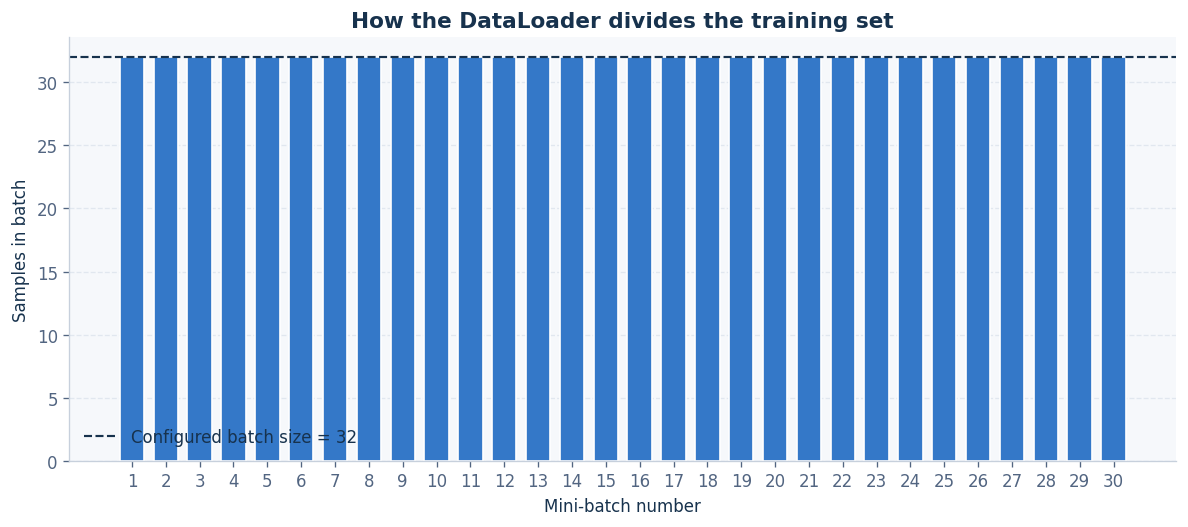

In [31]:
# Visualization: number of observations delivered in each mini-batch.
fig, ax = plt.subplots(figsize=(10, 4.5))
bar_colors = [BLUE] * len(batch_sizes)
if len(bar_colors) > 0 and batch_sizes[-1] < BATCH_SIZE:
    bar_colors[-1] = ORANGE
bars = ax.bar(batch_summary["batch"], batch_summary["samples"],
              color=bar_colors, width=0.72, edgecolor="white")
ax.axhline(BATCH_SIZE, color=NAVY, linestyle="--", linewidth=1.3,
           label=f"Configured batch size = {BATCH_SIZE}")
ax.set_title("How the DataLoader divides the training set")
ax.set_xlabel("Mini-batch number")
ax.set_ylabel("Samples in batch")
ax.set_xticks(batch_summary["batch"])
ax.grid(axis="y", linestyle="--")
ax.set_axisbelow(True)
ax.legend(frameon=False)
if len(batch_sizes) > 0 and batch_sizes[-1] < BATCH_SIZE:
    ax.annotate(f"Final batch: {batch_sizes[-1]} samples",
                xy=(batch_summary["batch"].iloc[-1], batch_sizes[-1]),
                xytext=(-75, -35), textcoords="offset points",
                arrowprops={"arrowstyle": "->", "color": NAVY},
                fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

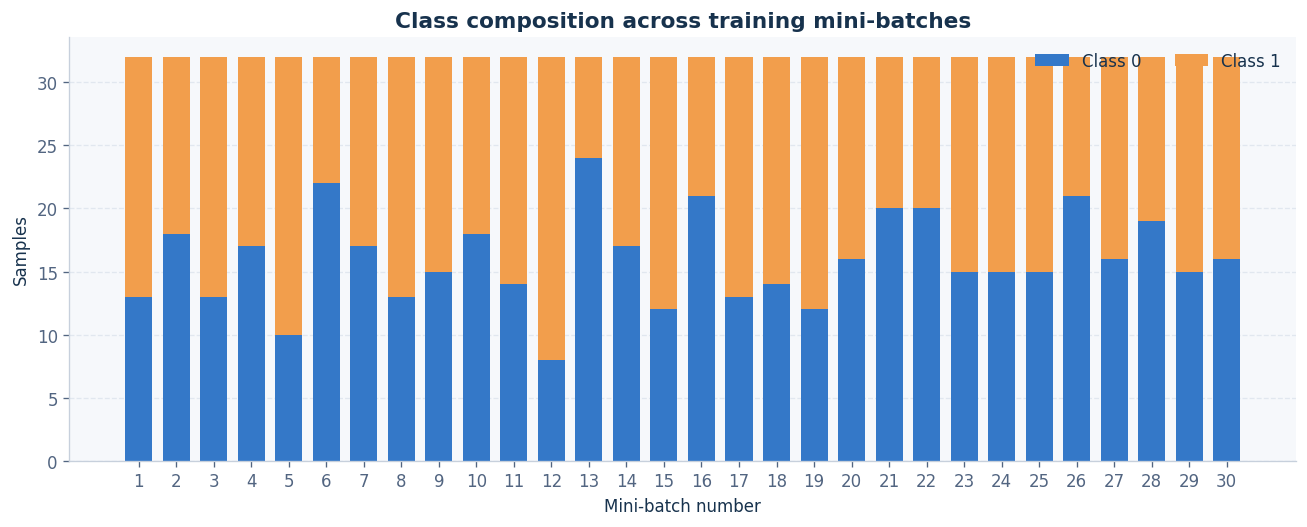

In [32]:
# Visualization: class composition for each mini-batch.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(batch_summary["batch"], batch_summary["class_0"],
       color=BLUE, label="Class 0", width=0.72)
ax.bar(batch_summary["batch"], batch_summary["class_1"],
       bottom=batch_summary["class_0"], color=ORANGE,
       label="Class 1", width=0.72)
ax.set_title("Class composition across training mini-batches")
ax.set_xlabel("Mini-batch number")
ax.set_ylabel("Samples")
ax.set_xticks(batch_summary["batch"])
ax.grid(axis="y", linestyle="--")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

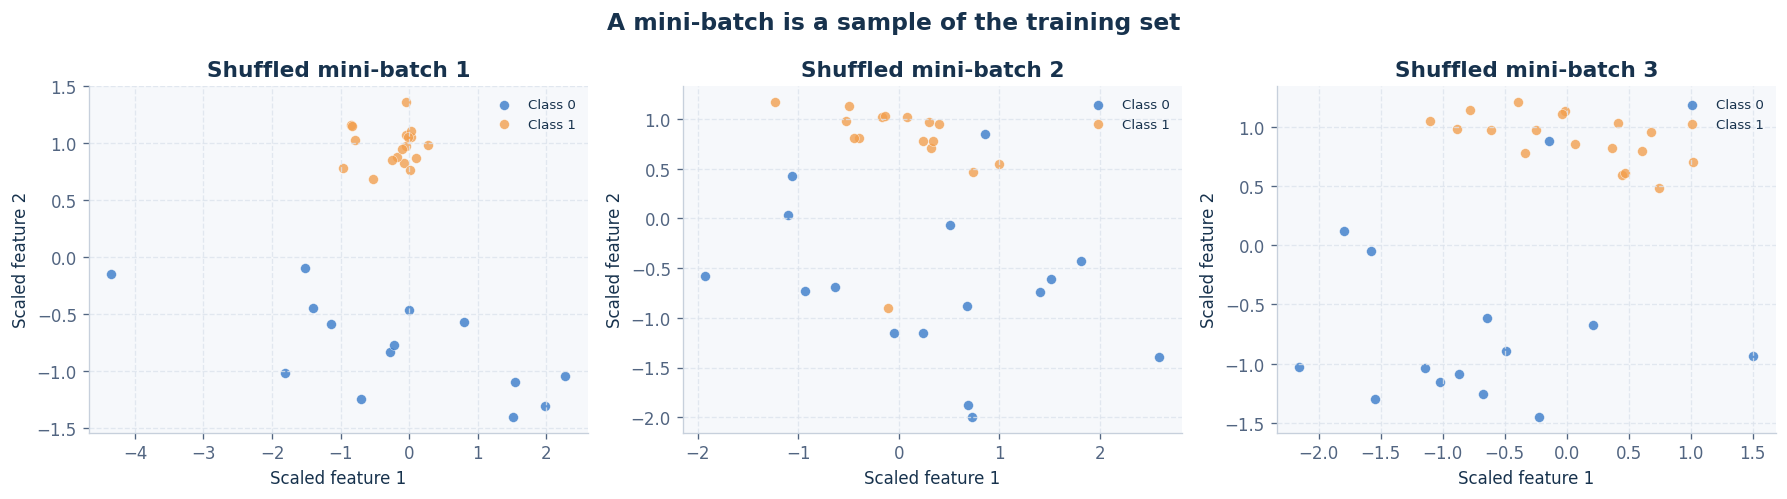

In [33]:
# Visualize three shuffled mini-batches in feature space.
preview_generator = torch.Generator().manual_seed(SEED + 1)
preview_loader = DataLoader(train_dataset, batch_size= BATCH_SIZE,
                            shuffle=True, generator=preview_generator)
preview_batches = [next(iter(preview_loader))]
iterator = iter(preview_loader)
preview_batches = []
for _ in range(3):
    try:
        preview_batches.append(next(iterator))
    except StopIteration:
        break

fig, axes = plt.subplots(1, len(preview_batches), figsize=(5 * len(preview_batches), 4.2), squeeze=False)
for batch_no, (features_batch, labels_batch) in enumerate(preview_batches, start=1):
    ax = axes[0, batch_no - 1]
    for label, color in CLASS_COLORS.items():
        mask = labels_batch.numpy() == label
        ax.scatter(features_batch.numpy()[mask, 0], features_batch.numpy()[mask, 1],
                   s=35, color=color, alpha=0.78, label=class_names[label],
                   edgecolors="white", linewidths=0.3)
    ax.set_title(f"Shuffled mini-batch {batch_no}")
    ax.set_xlabel("Scaled feature 1")
    ax.set_ylabel("Scaled feature 2")
    ax.grid(linestyle="--")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("A mini-batch is a sample of the training set", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [34]:
# Demonstrate shuffle=True versus shuffle=False.
ordered_loader = DataLoader(train_dataset, batch_size=12, shuffle=False)
shuffled_loader = DataLoader(
    train_dataset,
    batch_size=12,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED + 10),
)

ordered_first_batch = next(iter(ordered_loader))[0]
shuffled_first_batch = next(iter(shuffled_loader))[0]

print("First ordered batch (scaled feature 1):")
print(ordered_first_batch[:, 0].round(decimals=2).tolist())
print("\nFirst shuffled batch (scaled feature 1):")
print(shuffled_first_batch[:, 0].round(decimals=2).tolist())
print("\nAre the first batches in the same order?", torch.equal(ordered_first_batch, shuffled_first_batch))

First ordered batch (scaled feature 1):
[1.149999976158142, 0.8600000143051147, -0.05999999865889549, -0.18000000715255737, 0.5400000214576721, -1.8300000429153442, 0.25999999046325684, 0.029999999329447746, -0.14000000059604645, -0.550000011920929, 0.41999998688697815, 0.17000000178813934]

First shuffled batch (scaled feature 1):
[-0.4699999988079071, -0.15000000596046448, 1.5299999713897705, 0.14000000059604645, -0.1899999976158142, 0.5600000023841858, -0.029999999329447746, -0.75, -0.3700000047683716, -0.10999999940395355, -0.3199999928474426, 0.17000000178813934]

Are the first batches in the same order? False


### What does `drop_last` do?

If the number of samples is not divisible by the batch size, the final batch is incomplete. With `drop_last=False` (the default), it is kept. With `drop_last=True`, it is discarded.

Keeping the final batch is usually appropriate. Dropping it can be useful in some training setups that require a fixed batch size, but it means some training samples are not used in that epoch.

In [35]:
small_demo_dataset = TensorDataset(torch.arange(10).float().unsqueeze(1), torch.arange(10))
keep_last_loader = DataLoader(small_demo_dataset, batch_size=4, shuffle=False, drop_last=False)
drop_last_loader = DataLoader(small_demo_dataset, batch_size=4, shuffle=False, drop_last=True)

keep_sizes = [len(labels) for _, labels in keep_last_loader]
drop_sizes = [len(labels) for _, labels in drop_last_loader]
print("10 samples, batch size 4")
print("drop_last=False -> batch sizes:", keep_sizes)
print("drop_last=True  -> batch sizes:", drop_sizes)

10 samples, batch size 4
drop_last=False -> batch sizes: [4, 4, 2]
drop_last=True  -> batch sizes: [4, 4]


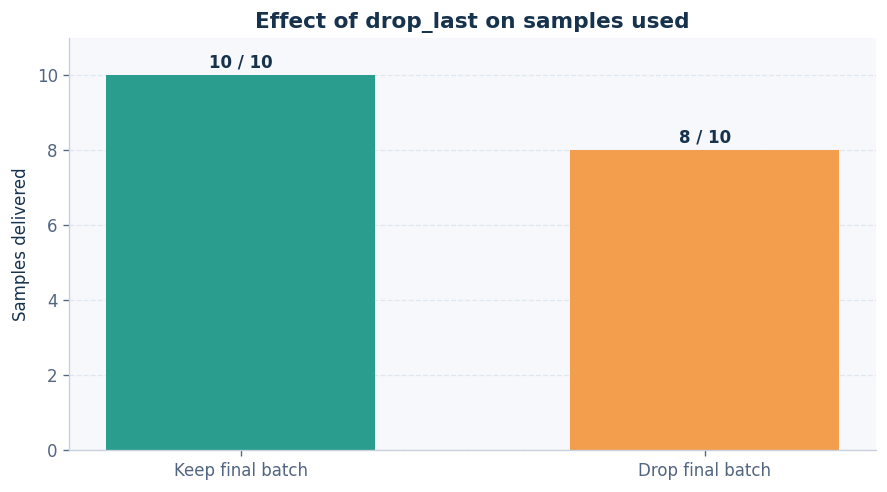

In [36]:
# A quick visual comparison of the two settings.
fig, ax = plt.subplots(figsize=(7.5, 4.2))
labels = ["Keep final batch", "Drop final batch"]
used = [sum(keep_sizes), sum(drop_sizes)]
bars = ax.bar(labels, used, color=[TEAL, ORANGE], width=0.58)
ax.set_title("Effect of drop_last on samples used")
ax.set_ylabel("Samples delivered")
ax.set_ylim(0, 11)
ax.grid(axis="y", linestyle="--")
ax.set_axisbelow(True)
for bar, value in zip(bars, used):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.2,
            f"{value} / 10", ha="center", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### `num_workers` and `pin_memory`

- `num_workers=0` loads data in the main process. It is simple and reliable for small in-memory datasets and notebook environments.
- Increasing `num_workers` can speed up expensive data loading, but it adds multiprocessing overhead. On Windows and in notebooks, worker code and entry-point handling need particular care.
- `pin_memory=True` can help host-to-GPU transfers when training on CUDA. It is generally unnecessary for CPU-only training.

Start simple, measure performance, and tune these settings only when data loading is a bottleneck.

## 7. Train a neural network with mini-batches

Now we use the `train_loader` and `test_loader` in a complete training workflow. The network is intentionally small because the goal is to understand how batches flow through the model, not to build a large architecture.

In [37]:
class SmallClassifier(nn.Module):
    def __init__(self, input_features: int, num_classes: int = 2):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)

model = SmallClassifier(input_features=X_train.shape[1]).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)
print("Model device:", next(model.parameters()).device)

SmallClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=2, bias=True)
  )
)
Model device: cpu


In [38]:
# Inspect the dimensions in a single forward pass before training.
example_batch_features, example_batch_labels = next(iter(train_loader))
example_logits = model(example_batch_features.to(DEVICE))
print("Input batch shape: ", example_batch_features.shape)
print("Output logits shape:", example_logits.shape)
print("Expected output: [batch_size, number_of_classes]")

Input batch shape:  torch.Size([32, 2])
Output logits shape: torch.Size([32, 2])
Expected output: [batch_size, number_of_classes]


### Training and evaluation functions

The training function performs forward propagation, calculates the loss, backpropagates gradients, and updates model weights for each mini-batch. During evaluation, gradients are disabled and the model is placed in evaluation mode.

In [39]:
def run_epoch(model, loader, criterion, optimizer=None):
    """Run one training or evaluation epoch and return average loss and accuracy."""
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for features_batch, labels_batch in loader:
            features_batch = features_batch.to(DEVICE, non_blocking=PIN_MEMORY)
            labels_batch = labels_batch.to(DEVICE, non_blocking=PIN_MEMORY)

            logits = model(features_batch)
            loss = criterion(logits, labels_batch)

            if is_training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

            batch_size = labels_batch.size(0)
            total_loss += loss.item() * batch_size
            predictions = logits.argmax(dim=1)
            total_correct += (predictions == labels_batch).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    average_accuracy = total_correct / total_samples
    return average_loss, average_accuracy

In [40]:
EPOCHS = 25
history = {
    "train_loss": [],
    "train_accuracy": [],
    "test_loss": [],
    "test_accuracy": [],
}

start_time = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, optimizer)
    test_loss, test_accuracy = run_epoch(model, test_loader, criterion)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["test_loss"].append(test_loss)
    history["test_accuracy"].append(test_accuracy)

    if epoch == 1 or epoch % 5 == 0 or epoch == EPOCHS:
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train loss: {train_loss:.4f} | train acc: {train_accuracy:.3f} | "
            f"test loss: {test_loss:.4f} | test acc: {test_accuracy:.3f}"
        )

training_seconds = time.perf_counter() - start_time
print(f"\nTraining completed in {training_seconds:.2f} seconds on {DEVICE}.")

Epoch 01/25 | train loss: 0.4253 | train acc: 0.861 | test loss: 0.0786 | test acc: 0.992
Epoch 05/25 | train loss: 0.1259 | train acc: 0.973 | test loss: 0.0502 | test acc: 0.988
Epoch 10/25 | train loss: 0.1239 | train acc: 0.974 | test loss: 0.0536 | test acc: 0.988
Epoch 15/25 | train loss: 0.1190 | train acc: 0.975 | test loss: 0.0607 | test acc: 0.988
Epoch 20/25 | train loss: 0.1177 | train acc: 0.976 | test loss: 0.0665 | test acc: 0.983
Epoch 25/25 | train loss: 0.1173 | train acc: 0.974 | test loss: 0.0628 | test acc: 0.988

Training completed in 1.28 seconds on cpu.


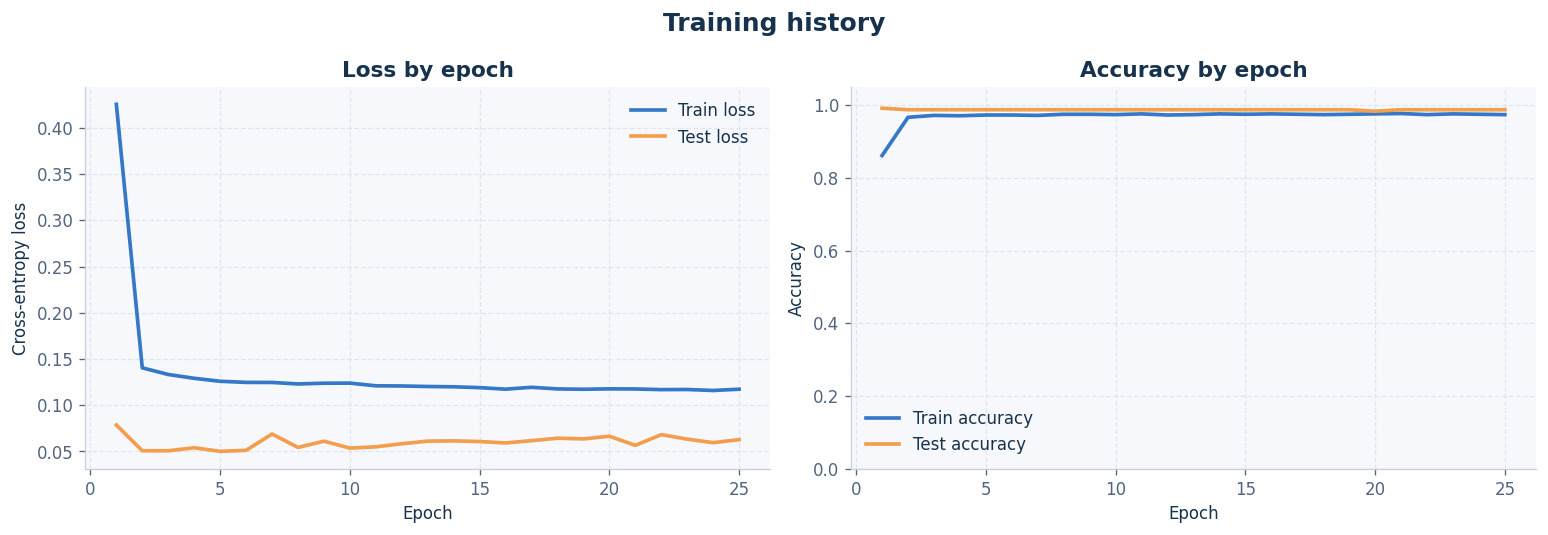

In [41]:
# Plot loss and accuracy curves.
epoch_numbers = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epoch_numbers, history["train_loss"], color=BLUE, linewidth=2.2, label="Train loss")
axes[0].plot(epoch_numbers, history["test_loss"], color=ORANGE, linewidth=2.2, label="Test loss")
axes[0].set_title("Loss by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(frameon=False)
axes[0].grid(linestyle="--")

axes[1].plot(epoch_numbers, history["train_accuracy"], color=BLUE, linewidth=2.2, label="Train accuracy")
axes[1].plot(epoch_numbers, history["test_accuracy"], color=ORANGE, linewidth=2.2, label="Test accuracy")
axes[1].set_title("Accuracy by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.05)
axes[1].legend(frameon=False)
axes[1].grid(linestyle="--")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Training history", fontsize=15, fontweight="bold", color=NAVY)
plt.tight_layout()
plt.show()

## 8. Evaluate, visualize, and make predictions

We now evaluate the trained model on the held-out test set. We will inspect accuracy, a classification report, a confusion matrix, and a decision-boundary plot.

In [42]:
model.eval()
all_predictions = []
all_targets = []

with torch.no_grad():
    for features_batch, labels_batch in test_loader:
        logits = model(features_batch.to(DEVICE))
        predictions = logits.argmax(dim=1).cpu()
        all_predictions.extend(predictions.tolist())
        all_targets.extend(labels_batch.tolist())

final_accuracy = accuracy_score(all_targets, all_predictions)
print(f"Final test accuracy: {final_accuracy:.3f}")
print("\nClassification report:")
print(classification_report(
    all_targets,
    all_predictions,
    labels=[0, 1],
    target_names=["Class 0", "Class 1"],
    zero_division=0,
))

Final test accuracy: 0.988

Classification report:
              precision    recall  f1-score   support

     Class 0       0.98      0.99      0.99       120
     Class 1       0.99      0.98      0.99       120

    accuracy                           0.99       240
   macro avg       0.99      0.99      0.99       240
weighted avg       0.99      0.99      0.99       240



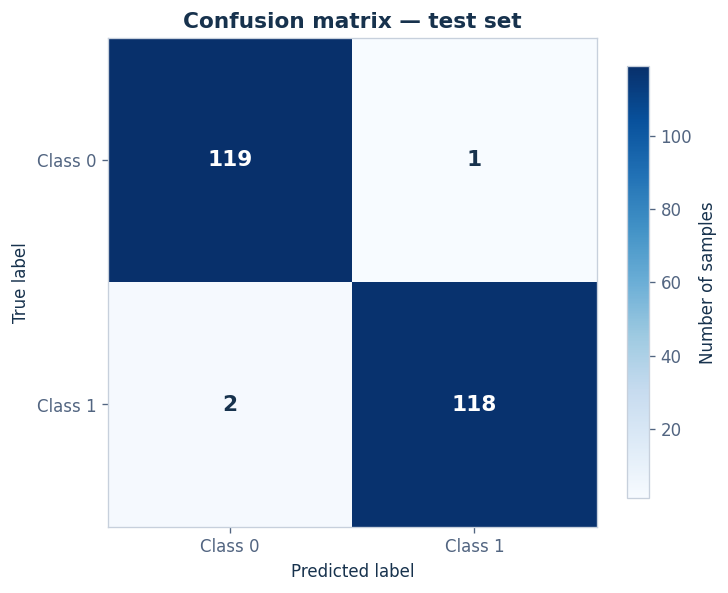

In [43]:
# Confusion matrix: rows are true labels; columns are predicted labels.
cm = confusion_matrix(all_targets, all_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.2, 5.2))
image = ax.imshow(cm, cmap="Blues")
ax.set_title("Confusion matrix — test set")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks([0, 1], ["Class 0", "Class 1"])
ax.set_yticks([0, 1], ["Class 0", "Class 1"])
threshold = cm.max() / 2 if cm.max() else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else NAVY,
                fontsize=13, fontweight="bold")
fig.colorbar(image, ax=ax, shrink=0.82, label="Number of samples")
plt.tight_layout()
plt.show()

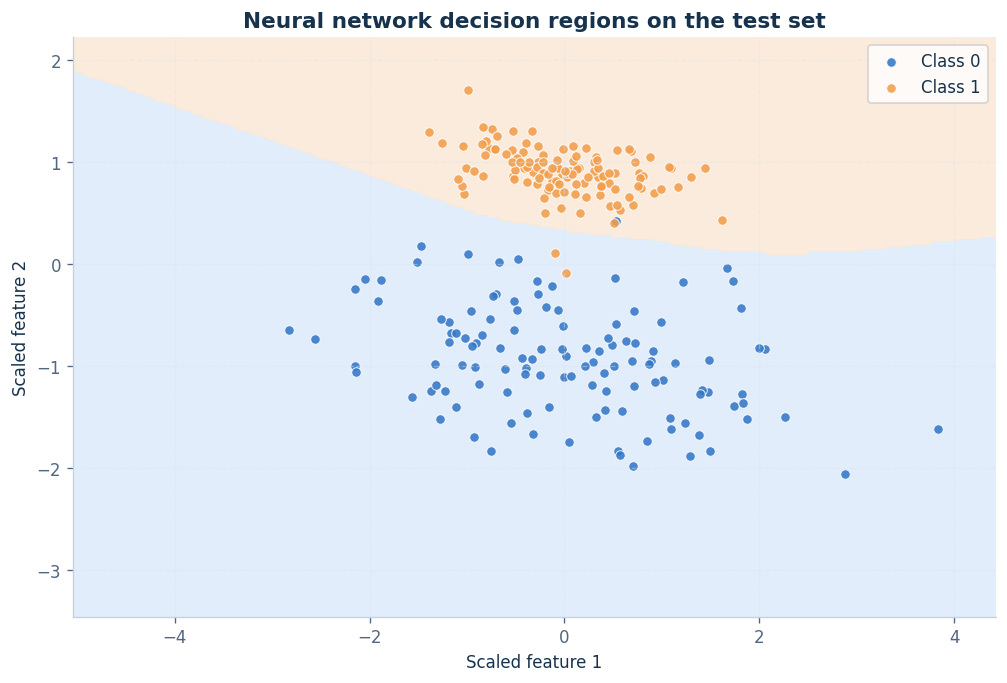

In [44]:
# Draw the learned decision boundary in the scaled feature space.
model.eval()
x_min, x_max = X_train[:, 0].min().item() - 0.7, X_train[:, 0].max().item() + 0.7
y_min, y_max = X_train[:, 1].min().item() - 0.7, X_train[:, 1].max().item() + 0.7
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 240),
    np.linspace(y_min, y_max, 240),
)
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=DEVICE)
with torch.no_grad():
    grid_predictions = model(grid).argmax(dim=1).cpu().numpy().reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8.5, 5.8))
ax.contourf(xx, yy, grid_predictions, levels=[-0.5, 0.5, 1.5],
            colors=["#DCEBFA", "#FCE8D5"], alpha=0.8)
for label, color in CLASS_COLORS.items():
    mask = y_test_np == label
    ax.scatter(X_test[mask, 0].numpy(), X_test[mask, 1].numpy(),
               color=color, edgecolors="white", linewidths=0.6,
               s=33, alpha=0.88, label=class_names[label])
ax.set_title("Neural network decision regions on the test set")
ax.set_xlabel("Scaled feature 1")
ax.set_ylabel("Scaled feature 2")
ax.legend(frameon=True, facecolor="white")
ax.grid(linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [45]:
# Predict the class for a new raw observation.
new_observation = np.array([[0.5, -0.8]], dtype=np.float32)
new_observation_scaled = scaler.transform(new_observation)
new_tensor = torch.tensor(new_observation_scaled, dtype=torch.float32, device=DEVICE)

model.eval()
with torch.no_grad():
    logits = model(new_tensor)
    probabilities = torch.softmax(logits, dim=1).cpu().numpy()[0]
    predicted_class = int(probabilities.argmax())

print("Raw observation:", new_observation.tolist())
print("Predicted class:", predicted_class, f"({class_names[predicted_class]})")
print("Class probabilities:", {class_names[i]: round(float(p), 4) for i, p in enumerate(probabilities)})

Raw observation: [[0.5, -0.800000011920929]]
Predicted class: 0 (Class 0)
Class probabilities: {'Class 0': 0.9751, 'Class 1': 0.0249}


## 9. Summary and practice tasks

### Key concepts to remember

| Concept | Responsibility |
|---|---|
| `Dataset` | Defines how to access one sample and its label |
| `__len__()` | Reports the number of samples |
| `__getitem__()` | Returns one indexed sample |
| `DataLoader` | Creates an iterable over samples or mini-batches |
| `batch_size` | Controls the number of samples in each batch |
| `shuffle=True` | Randomizes sample order when an iteration begins |
| `drop_last=True` | Discards an incomplete final batch |
| `num_workers` | Controls subprocesses used for data loading |
| `pin_memory=True` | Can improve CPU-to-CUDA transfer performance |

### Common mistakes and how to avoid them

1. **Mismatched lengths:** the feature tensor and label tensor must contain the same number of samples.
2. **Wrong dtypes:** use floating-point features and integer class-index labels for this `CrossEntropyLoss` example.
3. **Wrong label shape:** for class-index classification, labels should normally have shape `[batch_size]`, not `[batch_size, 1]`.
4. **Test leakage:** fit preprocessing steps such as `StandardScaler` on training data only.
5. **Forgetting `model.train()` / `model.eval()`:** use the correct mode during training and evaluation.
6. **Assuming every batch is full:** with `drop_last=False`, the final batch can be smaller.
7. **Over-tuning workers too early:** begin with `num_workers=0`, measure, then optimize if loading is actually slow.

### Hands-on practice

Try these modifications and observe how the output changes:

- Change `BATCH_SIZE` to `16`, `64`, and `128`. Recreate `train_loader` and compare the number of batches.
- Set `shuffle=False` for training. Compare training curves across runs.
- Set `drop_last=True`. Confirm how many training samples are delivered in one epoch.
- Add a third hidden layer to `SmallClassifier` and compare test performance.
- Increase the number of generated samples to `5_000` and compare training time.
- Replace the synthetic data with a real tabular dataset while keeping the same `Dataset` interface.

### Final takeaway

A well-designed `Dataset` keeps sample access clean and reusable. A well-configured `DataLoader` turns those samples into reliable mini-batches. Together, they form the foundation of most PyTorch training pipelines—from small tabular projects to large image and text datasets.

---

**End of notebook**  ·  *PyTorch fundamentals — Dataset & DataLoader*